In [110]:
print("This is Data science Related Project")

This is Data science Related Project


In [111]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [240]:
data=pd.read_csv('/home/ubuntu/ds/LR/ForestFire/Algerian_forest_fires_dataset_UPDATE.csv',header=1)

In [241]:
data

,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes
0,01,06,2012,29,57,18,0,65.7,3.4,7.6,1.3,3.4,0.5,not fire
1,02,06,2012,29,61,13,1.3,64.4,4.1,7.6,1,3.9,0.4,not fire
2,03,06,2012,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0.1,not fire
3,04,06,2012,25,89,13,2.5,28.6,1.3,6.9,0,1.7,0,not fire
4,05,06,2012,27,77,16,0,64.8,3,14.2,1.2,3.9,0.5,not fire
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
241,26,09,2012,30,65,14,0,85.4,16,44.5,4.5,16.9,6.5,fire
242,27,09,2012,28,87,15,4.4,41.1,6.5,8,0.1,6.2,0,not fire
243,28,09,2012,27,87,29,0.5,45.9,3.5,7.9,0.4,3.4,0.2,not fire
244,29,09,2012,24,54,18,0.1,79.7,4.3,15.2,1.7,5.1,0.7,not fire


In [242]:
type(data)

pandas.core.frame.DataFrame

In [243]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 246 entries, 0 to 245
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   day          246 non-null    object
 1   month        245 non-null    object
 2   year         245 non-null    object
 3   Temperature  245 non-null    object
 4    RH          245 non-null    object
 5    Ws          245 non-null    object
 6   Rain         245 non-null    object
 7   FFMC         245 non-null    object
 8   DMC          245 non-null    object
 9   DC           245 non-null    object
 10  ISI          245 non-null    object
 11  BUI          245 non-null    object
 12  FWI          245 non-null    object
 13  Classes      244 non-null    object
dtypes: object(14)
memory usage: 27.0+ KB


## data cleaning

In [244]:
data.index

RangeIndex(start=0, stop=246, step=1)

In [245]:
data.iloc[120:130]

,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes
120,29,09,2012,26,80,16,1.8,47.4,2.9,7.7,0.3,3,0.1,not fire
121,30,09,2012,25,78,14,1.4,45,1.9,7.5,0.2,2.4,0.1,not fire
122,Sidi-Bel Abbes Region Dataset,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
123,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes
124,01,06,2012,32,71,12,0.7,57.1,2.5,8.2,0.6,2.8,0.2,not fire
125,02,06,2012,30,73,13,4,55.7,2.7,7.8,0.6,2.9,0.2,not fire
126,03,06,2012,29,80,14,2,48.7,2.2,7.6,0.3,2.6,0.1,not fire
127,04,06,2012,30,64,14,0,79.4,5.2,15.4,2.2,5.6,1,not fire
128,05,06,2012,32,60,14,0.2,77.1,6,17.6,1.8,6.5,0.9,not fire
129,06,06,2012,35,54,11,0.1,83.7,8.4,26.3,3.1,9.3,3.1,fire


In [246]:
data[data.isnull().any(axis=1)]

,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes
122,Sidi-Bel Abbes Region Dataset,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
167,14,07,2012,37,37,18,0.2,88.9,12.9,14.6 9,12.5,10.4,fire,NaN


In [247]:
data.loc[:122,'Region']=0
data.loc[122:,'Region']=1
df=data

In [248]:
df

,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
0,01,06,2012,29,57,18,0,65.7,3.4,7.6,1.3,3.4,0.5,not fire,0.0
1,02,06,2012,29,61,13,1.3,64.4,4.1,7.6,1,3.9,0.4,not fire,0.0
2,03,06,2012,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0.1,not fire,0.0
3,04,06,2012,25,89,13,2.5,28.6,1.3,6.9,0,1.7,0,not fire,0.0
4,05,06,2012,27,77,16,0,64.8,3,14.2,1.2,3.9,0.5,not fire,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
241,26,09,2012,30,65,14,0,85.4,16,44.5,4.5,16.9,6.5,fire,1.0
242,27,09,2012,28,87,15,4.4,41.1,6.5,8,0.1,6.2,0,not fire,1.0
243,28,09,2012,27,87,29,0.5,45.9,3.5,7.9,0.4,3.4,0.2,not fire,1.0
244,29,09,2012,24,54,18,0.1,79.7,4.3,15.2,1.7,5.1,0.7,not fire,1.0


In [249]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 246 entries, 0 to 245
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   day          246 non-null    object 
 1   month        245 non-null    object 
 2   year         245 non-null    object 
 3   Temperature  245 non-null    object 
 4    RH          245 non-null    object 
 5    Ws          245 non-null    object 
 6   Rain         245 non-null    object 
 7   FFMC         245 non-null    object 
 8   DMC          245 non-null    object 
 9   DC           245 non-null    object 
 10  ISI          245 non-null    object 
 11  BUI          245 non-null    object 
 12  FWI          245 non-null    object 
 13  Classes      244 non-null    object 
 14  Region       246 non-null    float64
dtypes: float64(1), object(14)
memory usage: 29.0+ KB


In [250]:
df[["Region"]]=df[['Region']].astype(int)

In [251]:
df.iloc[120:125]

,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
120,29,09,2012,26,80,16,1.8,47.4,2.9,7.7,0.3,3,0.1,not fire,0
121,30,09,2012,25,78,14,1.4,45,1.9,7.5,0.2,2.4,0.1,not fire,0
122,Sidi-Bel Abbes Region Dataset,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
123,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,1
124,01,06,2012,32,71,12,0.7,57.1,2.5,8.2,0.6,2.8,0.2,not fire,1


In [252]:
df.isnull().sum()

day            0
month          1
year           1
Temperature    1
 RH            1
 Ws            1
Rain           1
FFMC           1
DMC            1
DC             1
ISI            1
BUI            1
FWI            1
Classes        2
Region         0
dtype: int64

In [253]:
### dropna-> drops any row that has nan value ... reset_index--> resets the index ... then all assigned back to df

In [254]:
## remove null values 
df=df.drop([122,123]).reset_index(drop=True)
df

,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
0,01,06,2012,29,57,18,0,65.7,3.4,7.6,1.3,3.4,0.5,not fire,0
1,02,06,2012,29,61,13,1.3,64.4,4.1,7.6,1,3.9,0.4,not fire,0
2,03,06,2012,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0.1,not fire,0
3,04,06,2012,25,89,13,2.5,28.6,1.3,6.9,0,1.7,0,not fire,0
4,05,06,2012,27,77,16,0,64.8,3,14.2,1.2,3.9,0.5,not fire,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
239,26,09,2012,30,65,14,0,85.4,16,44.5,4.5,16.9,6.5,fire,1
240,27,09,2012,28,87,15,4.4,41.1,6.5,8,0.1,6.2,0,not fire,1
241,28,09,2012,27,87,29,0.5,45.9,3.5,7.9,0.4,3.4,0.2,not fire,1
242,29,09,2012,24,54,18,0.1,79.7,4.3,15.2,1.7,5.1,0.7,not fire,1


In [255]:
df.iloc[120:125]

,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
120,29,09,2012,26,80,16,1.8,47.4,2.9,7.7,0.3,3,0.1,not fire,0
121,30,09,2012,25,78,14,1.4,45,1.9,7.5,0.2,2.4,0.1,not fire,0
122,01,06,2012,32,71,12,0.7,57.1,2.5,8.2,0.6,2.8,0.2,not fire,1
123,02,06,2012,30,73,13,4,55.7,2.7,7.8,0.6,2.9,0.2,not fire,1
124,03,06,2012,29,80,14,2,48.7,2.2,7.6,0.3,2.6,0.1,not fire,1


In [256]:
df.isnull().sum()

day            0
month          0
year           0
Temperature    0
 RH            0
 Ws            0
Rain           0
FFMC           0
DMC            0
DC             0
ISI            0
BUI            0
FWI            0
Classes        1
Region         0
dtype: int64

## Feature engineering / EDA

In [257]:
df.head()

,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
0,01,06,2012,29,57,18,0,65.7,3.4,7.6,1.3,3.4,0.5,not fire,0
1,02,06,2012,29,61,13,1.3,64.4,4.1,7.6,1,3.9,0.4,not fire,0
2,03,06,2012,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0.1,not fire,0
3,04,06,2012,25,89,13,2.5,28.6,1.3,6.9,0,1.7,0,not fire,0
4,05,06,2012,27,77,16,0,64.8,3,14.2,1.2,3.9,0.5,not fire,0


In [258]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   day          244 non-null    object
 1   month        244 non-null    object
 2   year         244 non-null    object
 3   Temperature  244 non-null    object
 4    RH          244 non-null    object
 5    Ws          244 non-null    object
 6   Rain         244 non-null    object
 7   FFMC         244 non-null    object
 8   DMC          244 non-null    object
 9   DC           244 non-null    object
 10  ISI          244 non-null    object
 11  BUI          244 non-null    object
 12  FWI          244 non-null    object
 13  Classes      243 non-null    object
 14  Region       244 non-null    int64 
dtypes: int64(1), object(14)
memory usage: 28.7+ KB


In [259]:
df=df.drop(['day','year'],axis=1)

In [260]:
df 

,month,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
0,06,29,57,18,0,65.7,3.4,7.6,1.3,3.4,0.5,not fire,0
1,06,29,61,13,1.3,64.4,4.1,7.6,1,3.9,0.4,not fire,0
2,06,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0.1,not fire,0
3,06,25,89,13,2.5,28.6,1.3,6.9,0,1.7,0,not fire,0
4,06,27,77,16,0,64.8,3,14.2,1.2,3.9,0.5,not fire,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
239,09,30,65,14,0,85.4,16,44.5,4.5,16.9,6.5,fire,1
240,09,28,87,15,4.4,41.1,6.5,8,0.1,6.2,0,not fire,1
241,09,27,87,29,0.5,45.9,3.5,7.9,0.4,3.4,0.2,not fire,1
242,09,24,54,18,0.1,79.7,4.3,15.2,1.7,5.1,0.7,not fire,1


In [261]:
df.columns

Index(['month', 'Temperature', ' RH', ' Ws', 'Rain ', 'FFMC', 'DMC', 'DC',
       'ISI', 'BUI', 'FWI', 'Classes  ', 'Region'],
      dtype='object')

In [262]:
df.columns=df.columns.str.strip()

In [263]:
df.columns

Index(['month', 'Temperature', 'RH', 'Ws', 'Rain', 'FFMC', 'DMC', 'DC', 'ISI',
       'BUI', 'FWI', 'Classes', 'Region'],
      dtype='object')

In [264]:
df[['month','Temperature', 'RH', 'Ws']]=df[['month','Temperature', 'RH', 'Ws']].astype(int)

In [265]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   month        244 non-null    int64 
 1   Temperature  244 non-null    int64 
 2   RH           244 non-null    int64 
 3   Ws           244 non-null    int64 
 4   Rain         244 non-null    object
 5   FFMC         244 non-null    object
 6   DMC          244 non-null    object
 7   DC           244 non-null    object
 8   ISI          244 non-null    object
 9   BUI          244 non-null    object
 10  FWI          244 non-null    object
 11  Classes      243 non-null    object
 12  Region       244 non-null    int64 
dtypes: int64(5), object(8)
memory usage: 24.9+ KB


In [266]:
cols = ['FFMC', 'DMC', 'DC', 'ISI', 'BUI', 'FWI']

df[df[cols].astype(str).apply(lambda x: x.str.contains(' ')).any(axis=1)]

,month,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
11,6,26,81,19,0,84,13.8,61.4,4.8,17.7,7.1,fire,0
165,7,37,37,18,0.2,88.9,12.9,14.6 9,12.5,10.4,fire,NaN,1


In [267]:
val1, val2 = df.loc[165, 'DC'].split()

In [268]:
df.loc[165, 'DC'] = float(val1)
df.loc[165, 'ISI'] = float(val2)
df.loc[165, 'BUI'] = 12.5
df.loc[165, 'FWI'] = 10.4
df.loc[165, 'Classes'] = 'fire'
df.loc[165, 'Region'] = 1

In [269]:
df[['Rain','FFMC', 'DMC', 'DC', 'ISI', 'BUI','FWI']]=df[['Rain','FFMC', 'DMC', 'DC', 'ISI', 'BUI','FWI']].astype(float)

In [270]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   month        244 non-null    int64  
 1   Temperature  244 non-null    int64  
 2   RH           244 non-null    int64  
 3   Ws           244 non-null    int64  
 4   Rain         244 non-null    float64
 5   FFMC         244 non-null    float64
 6   DMC          244 non-null    float64
 7   DC           244 non-null    float64
 8   ISI          244 non-null    float64
 9   BUI          244 non-null    float64
 10  FWI          244 non-null    float64
 11  Classes      244 non-null    object 
 12  Region       244 non-null    int64  
dtypes: float64(7), int64(5), object(1)
memory usage: 24.9+ KB


In [271]:
df["Classes"].value_counts()

Classes
fire             131
not fire         101
fire               5
fire               2
not fire           2
not fire           1
not fire           1
not fire           1
Name: count, dtype: int64

In [272]:
fire=131+5+2
notfire=101+2+1+1+1
fire, notfire

(138, 106)

In [273]:
df['Classes'].unique()

array(['not fire   ', 'fire   ', 'fire', 'fire ', 'not fire', 'not fire ',
       'not fire     ', 'not fire    '], dtype=object)

In [274]:
df

,month,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
0,6,29,57,18,0.0,65.7,3.4,7.6,1.3,3.4,0.5,not fire,0
1,6,29,61,13,1.3,64.4,4.1,7.6,1.0,3.9,0.4,not fire,0
2,6,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0.1,not fire,0
3,6,25,89,13,2.5,28.6,1.3,6.9,0.0,1.7,0.0,not fire,0
4,6,27,77,16,0.0,64.8,3.0,14.2,1.2,3.9,0.5,not fire,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
239,9,30,65,14,0.0,85.4,16.0,44.5,4.5,16.9,6.5,fire,1
240,9,28,87,15,4.4,41.1,6.5,8.0,0.1,6.2,0.0,not fire,1
241,9,27,87,29,0.5,45.9,3.5,7.9,0.4,3.4,0.2,not fire,1
242,9,24,54,18,0.1,79.7,4.3,15.2,1.7,5.1,0.7,not fire,1


In [275]:
df.head(10)

,month,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
0,6,29,57,18,0.0,65.7,3.4,7.6,1.3,3.4,0.5,not fire,0
1,6,29,61,13,1.3,64.4,4.1,7.6,1.0,3.9,0.4,not fire,0
2,6,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0.1,not fire,0
3,6,25,89,13,2.5,28.6,1.3,6.9,0.0,1.7,0.0,not fire,0
4,6,27,77,16,0.0,64.8,3.0,14.2,1.2,3.9,0.5,not fire,0
5,6,31,67,14,0.0,82.6,5.8,22.2,3.1,7.0,2.5,fire,0
6,6,33,54,13,0.0,88.2,9.9,30.5,6.4,10.9,7.2,fire,0
7,6,30,73,15,0.0,86.6,12.1,38.3,5.6,13.5,7.1,fire,0
8,6,25,88,13,0.2,52.9,7.9,38.8,0.4,10.5,0.3,not fire,0
9,6,28,79,12,0.0,73.2,9.5,46.3,1.3,12.6,0.9,not fire,0


In [276]:
df["Classes"]=np.where(df["Classes"].str.contains('not'),0,1)

In [277]:
df["Classes"].value_counts()

Classes
1    138
0    106
Name: count, dtype: int64

In [278]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   month        244 non-null    int64  
 1   Temperature  244 non-null    int64  
 2   RH           244 non-null    int64  
 3   Ws           244 non-null    int64  
 4   Rain         244 non-null    float64
 5   FFMC         244 non-null    float64
 6   DMC          244 non-null    float64
 7   DC           244 non-null    float64
 8   ISI          244 non-null    float64
 9   BUI          244 non-null    float64
 10  FWI          244 non-null    float64
 11  Classes      244 non-null    int64  
 12  Region       244 non-null    int64  
dtypes: float64(7), int64(6)
memory usage: 24.9 KB


In [279]:
df.describe()

,month,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
count,244.000000,244.000000,244.000000,244.000000,244.000000,244.000000,244.000000,244.000000,244.000000,244.000000,244.000000,244.000000,244.000000
mean,7.500000,32.172131,61.938525,15.504098,0.760656,77.887705,14.673361,49.288115,4.759836,16.673361,7.049180,0.565574,0.500000
std,1.112961,3.633843,14.884200,2.810178,1.999406,14.337571,12.368039,47.619662,4.154628,14.201648,7.428366,0.496700,0.501028
min,6.000000,22.000000,21.000000,6.000000,0.000000,28.600000,0.700000,6.900000,0.000000,1.100000,0.000000,0.000000,0.000000
25%,7.000000,30.000000,52.000000,14.000000,0.000000,72.075000,5.800000,13.275000,1.400000,6.000000,0.700000,0.000000,0.000000
50%,7.500000,32.000000,63.000000,15.000000,0.000000,83.500000,11.300000,33.100000,3.500000,12.450000,4.450000,1.000000,0.500000
75%,8.000000,35.000000,73.250000,17.000000,0.500000,88.300000,20.750000,68.150000,7.300000,22.525000,11.375000,1.000000,1.000000
max,9.000000,42.000000,90.000000,29.000000,16.800000,96.000000,65.900000,220.400000,19.000000,68.000000,31.100000,1.000000,1.000000


In [280]:
df.corr()

,month,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
month,1.000000e+00,-0.059017,-0.037884,-0.041447,0.035322,0.015577,0.068178,0.127672,0.063545,0.085567,0.081732,0.022333,-9.586232e-17
Temperature,-5.901677e-02,1.000000,-0.654443,-0.278132,-0.326786,0.677491,0.483105,0.370498,0.605971,0.456415,0.566839,0.518119,2.734961e-01
RH,-3.788419e-02,-0.654443,1.000000,0.236084,0.222968,-0.645658,-0.405133,-0.220330,-0.688268,-0.349685,-0.580457,-0.435023,-4.064239e-01
Ws,-4.144673e-02,-0.278132,0.236084,1.000000,0.170169,-0.163255,-0.001246,0.076245,0.012245,0.030303,0.033957,-0.066529,-1.768290e-01
Rain,3.532207e-02,-0.326786,0.222968,0.170169,1.000000,-0.544045,-0.288548,-0.296804,-0.347862,-0.299409,-0.324755,-0.379449,-4.108006e-02
FFMC,1.557668e-02,0.677491,-0.645658,-0.163255,-0.544045,1.000000,0.602391,0.503910,0.740751,0.590251,0.691430,0.770114,2.246798e-01
DMC,6.817778e-02,0.483105,-0.405133,-0.001246,-0.288548,0.602391,1.000000,0.875358,0.678355,0.982206,0.875191,0.584188,1.910937e-01
DC,1.276719e-01,0.370498,-0.220330,0.076245,-0.296804,0.503910,0.875358,1.000000,0.503919,0.941672,0.737041,0.507122,-8.148947e-02
ISI,6.354476e-02,0.605971,-0.688268,0.012245,-0.347862,0.740751,0.678355,0.503919,1.000000,0.641351,0.922422,0.736142,2.662977e-01
BUI,8.556743e-02,0.456415,-0.349685,0.030303,-0.299409,0.590251,0.982206,0.941672,0.641351,1.000000,0.856912,0.584545,8.799645e-02


## Doing some visualisations

In [281]:
df1=df

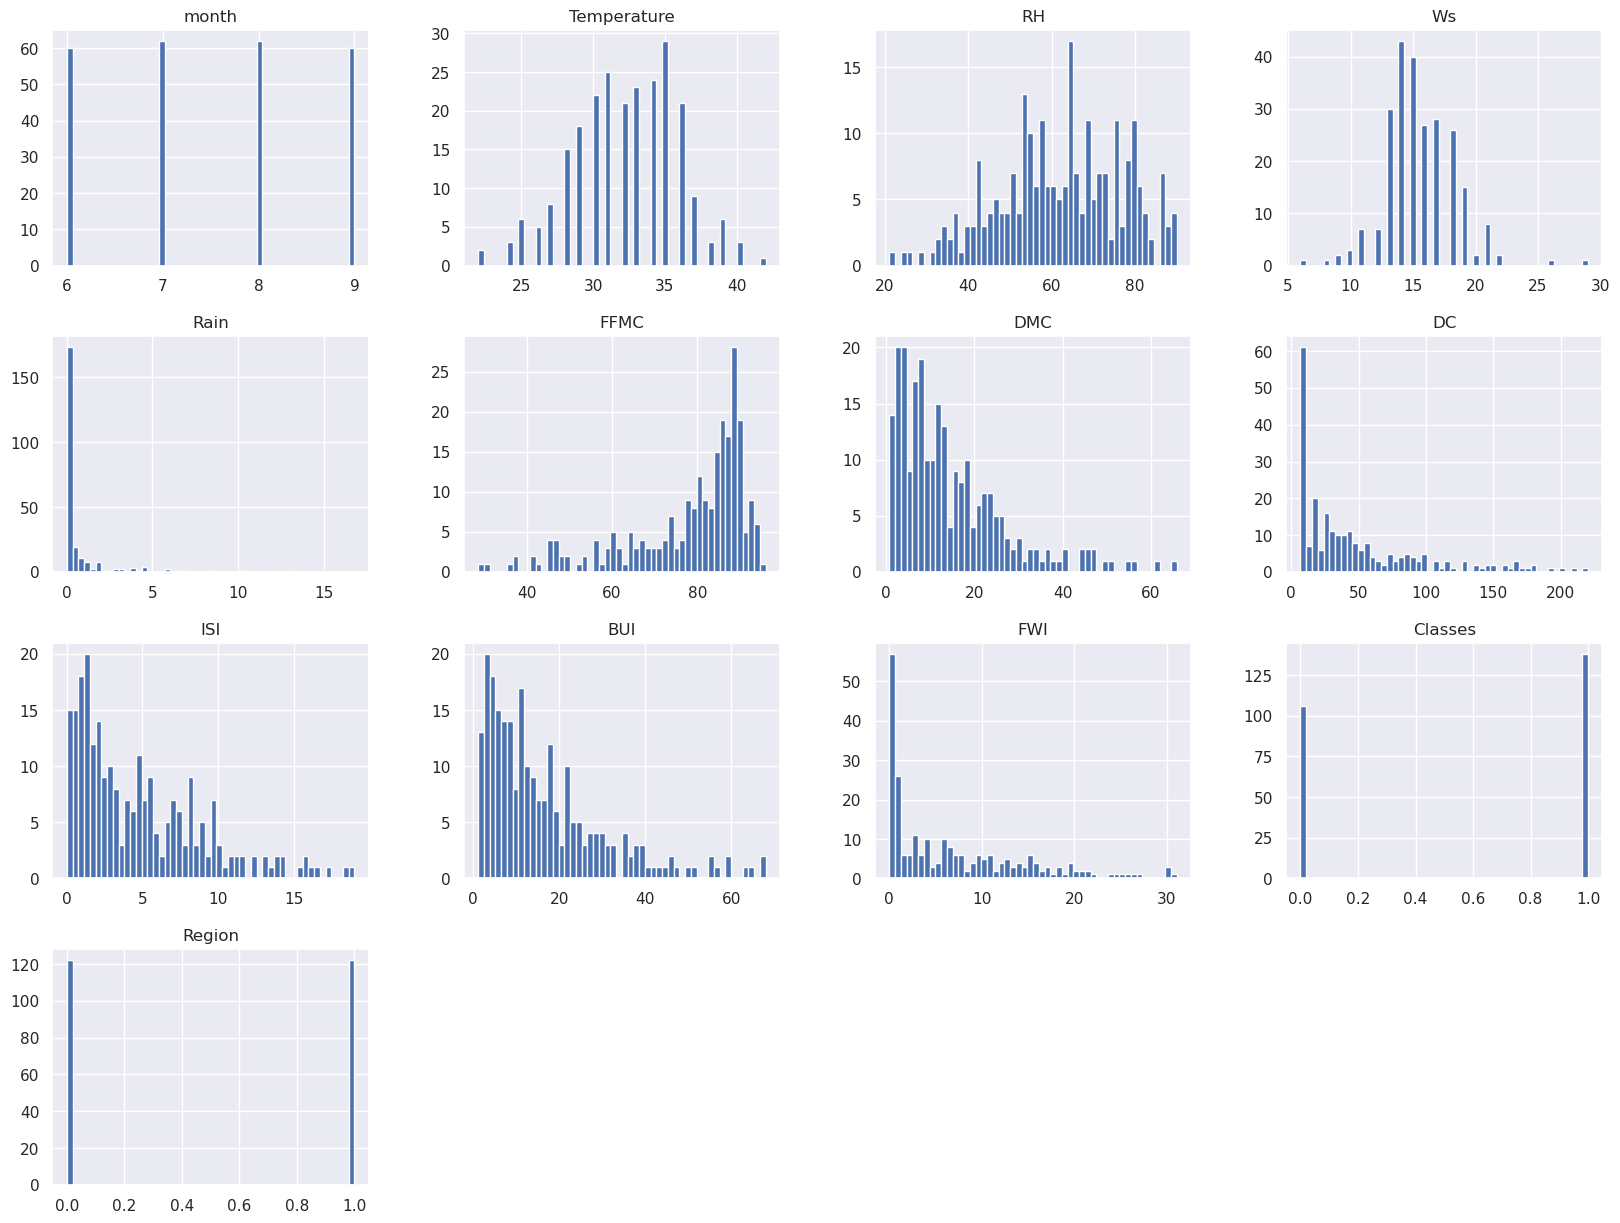

In [282]:
sns.set_theme()   # replaces plt.style.use('seaborn')

df1.hist(bins=50,figsize=(20,15))
plt.show()

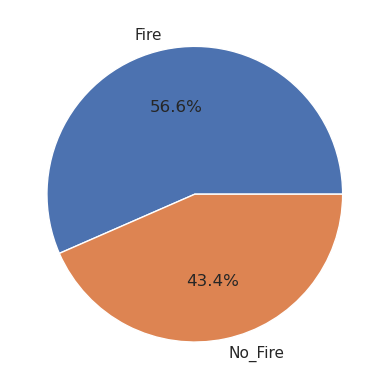

In [283]:
counts = df['Classes'].value_counts(normalize=True).reindex([1, 0]) * 100

plt.pie(counts, labels=['Fire', 'No_Fire'], autopct='%1.1f%%')
plt.show()

In [284]:
df["RH"].unique()

array([57, 61, 82, 89, 77, 67, 54, 73, 88, 79, 65, 81, 84, 78, 80, 55, 62,
       66, 64, 53, 47, 50, 68, 75, 76, 63, 69, 70, 59, 48, 45, 60, 51, 52,
       58, 86, 74, 71, 49, 44, 41, 42, 90, 87, 72, 46, 37, 36, 56, 43, 83,
       29, 34, 33, 35, 39, 31, 21, 40, 24, 38, 26])

<Axes: >

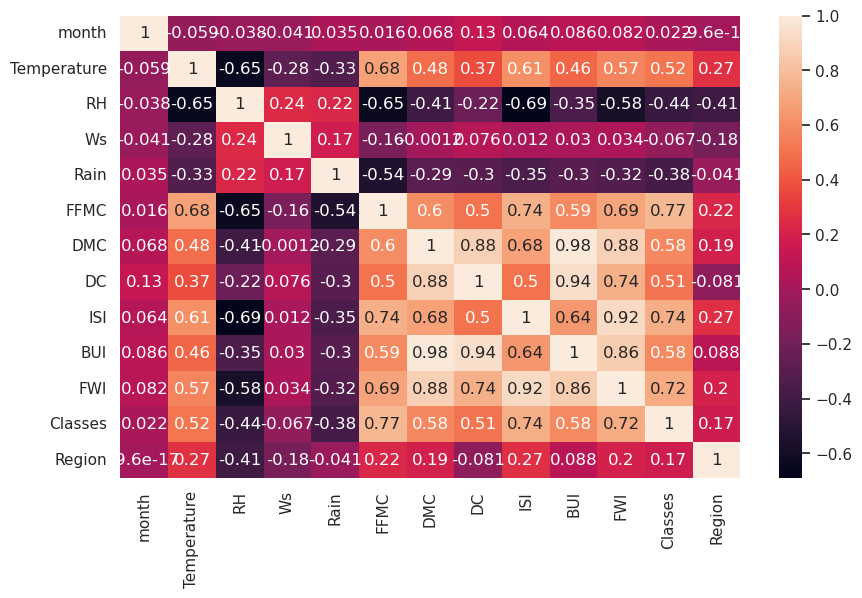

In [285]:
plt.figure(figsize=(10, 6))
sns.heatmap(df.corr(),annot=True)

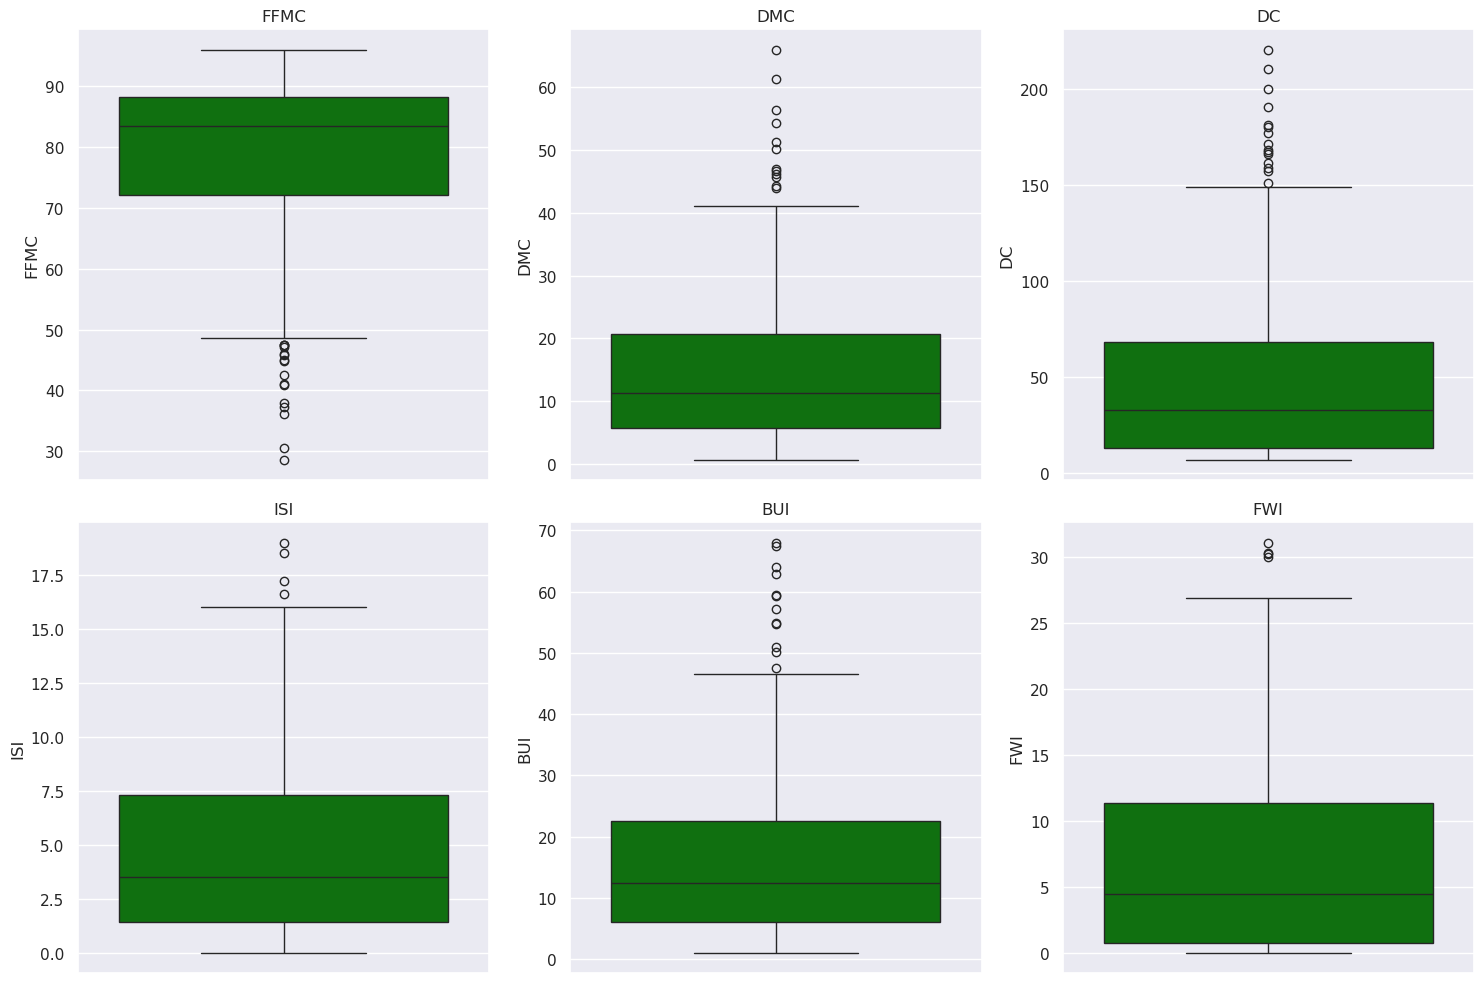

In [286]:
box=['FFMC', 'DMC', 'DC', 'ISI', 'BUI','FWI']

plt.figure(figsize=(15,10))

for idx, i in enumerate(box, 1):
    plt.subplot(2, 3, idx)
    sns.boxplot(y=df[i], color='green')
    plt.title(i)

plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'Fire Analysis of Brjaia Regions')

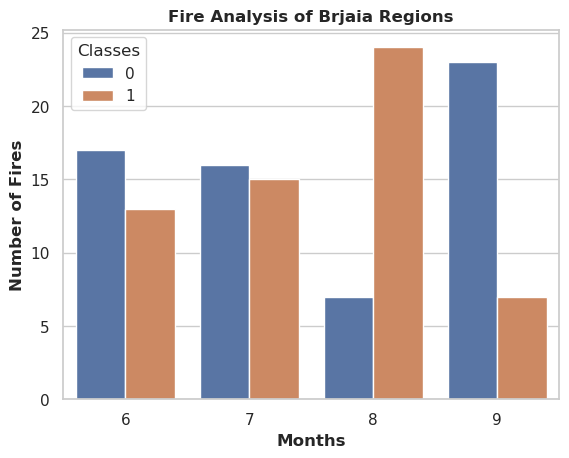

In [287]:
## Monthly Fire Analysis
dftemp=df.loc[df['Region']==0]
sns.set_style('whitegrid')
sns.countplot(x='month',hue='Classes',data=dftemp)
plt.ylabel('Number of Fires',weight='bold')
plt.xlabel('Months',weight='bold')
plt.title("Fire Analysis of Brjaia Regions",weight='bold')


Text(0.5, 1.0, 'Fire Analysis of Sidi- Bel Regions')

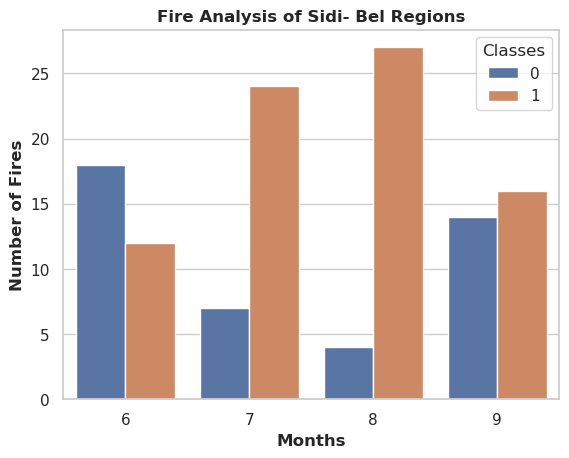

In [288]:
dftemp=df.loc[df['Region']==1]
sns.set_style('whitegrid')
sns.countplot(x='month',hue='Classes',data=dftemp)
plt.ylabel('Number of Fires',weight='bold')
plt.xlabel('Months',weight='bold')
plt.title("Fire Analysis of Sidi- Bel Regions",weight='bold')

In [289]:
df['Classes'].value_counts()

Classes
1    138
0    106
Name: count, dtype: int64

In [290]:
df.drop('month',axis=1,inplace=True)

## working on independent and dependent features 

In [291]:
df.head()

,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
0,29,57,18,0.0,65.7,3.4,7.6,1.3,3.4,0.5,0,0
1,29,61,13,1.3,64.4,4.1,7.6,1.0,3.9,0.4,0,0
2,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0.1,0,0
3,25,89,13,2.5,28.6,1.3,6.9,0.0,1.7,0.0,0,0
4,27,77,16,0.0,64.8,3.0,14.2,1.2,3.9,0.5,0,0


In [292]:
X=df.drop('FWI',axis=1)
y=df['FWI']

In [293]:
X

,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,Classes,Region
0,29,57,18,0.0,65.7,3.4,7.6,1.3,3.4,0,0
1,29,61,13,1.3,64.4,4.1,7.6,1.0,3.9,0,0
2,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0,0
3,25,89,13,2.5,28.6,1.3,6.9,0.0,1.7,0,0
4,27,77,16,0.0,64.8,3.0,14.2,1.2,3.9,0,0
...,...,...,...,...,...,...,...,...,...,...,...
239,30,65,14,0.0,85.4,16.0,44.5,4.5,16.9,1,1
240,28,87,15,4.4,41.1,6.5,8.0,0.1,6.2,0,1
241,27,87,29,0.5,45.9,3.5,7.9,0.4,3.4,0,1
242,24,54,18,0.1,79.7,4.3,15.2,1.7,5.1,0,1


In [294]:
y

0      0.5
1      0.4
2      0.1
3      0.0
4      0.5
      ... 
239    6.5
240    0.0
241    0.2
242    0.7
243    0.5
Name: FWI, Length: 244, dtype: float64

In [295]:
## train test split 
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25, random_state=42)

In [296]:
X_train.shape,X_test.shape,y_train.shape,y_test.shape

((183, 11), (61, 11), (183,), (61,))

In [297]:
## feature selection 
X_train.corr()

,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,Classes,Region
Temperature,1.000000,-0.664492,-0.249312,-0.375047,0.703238,0.485379,0.374673,0.607478,0.459776,0.512818,0.256099
RH,-0.664492,1.000000,0.235766,0.262550,-0.637201,-0.398168,-0.215075,-0.691612,-0.345860,-0.429397,-0.397053
Ws,-0.249312,0.235766,1.000000,0.262759,-0.169489,-0.013533,0.073923,0.011260,0.023266,-0.078171,-0.229797
Rain,-0.375047,0.262550,0.262759,1.000000,-0.585018,-0.291338,-0.296114,-0.354277,-0.301666,-0.394262,-0.096985
FFMC,0.703238,-0.637201,-0.169489,-0.585018,1.000000,0.602278,0.508348,0.745644,0.593647,0.774398,0.237434
DMC,0.485379,-0.398168,-0.013533,-0.291338,0.602278,1.000000,0.877045,0.657983,0.982049,0.580530,0.197489
DC,0.374673,-0.215075,0.073923,-0.296114,0.508348,0.877045,1.000000,0.503266,0.940947,0.501279,-0.079217
ISI,0.607478,-0.691612,0.011260,-0.354277,0.745644,0.657983,0.503266,1.000000,0.631317,0.745431,0.264224
BUI,0.459776,-0.345860,0.023266,-0.301666,0.593647,0.982049,0.940947,0.631317,1.000000,0.583986,0.093371
Classes,0.512818,-0.429397,-0.078171,-0.394262,0.774398,0.580530,0.501279,0.745431,0.583986,1.000000,0.158763


<Axes: >

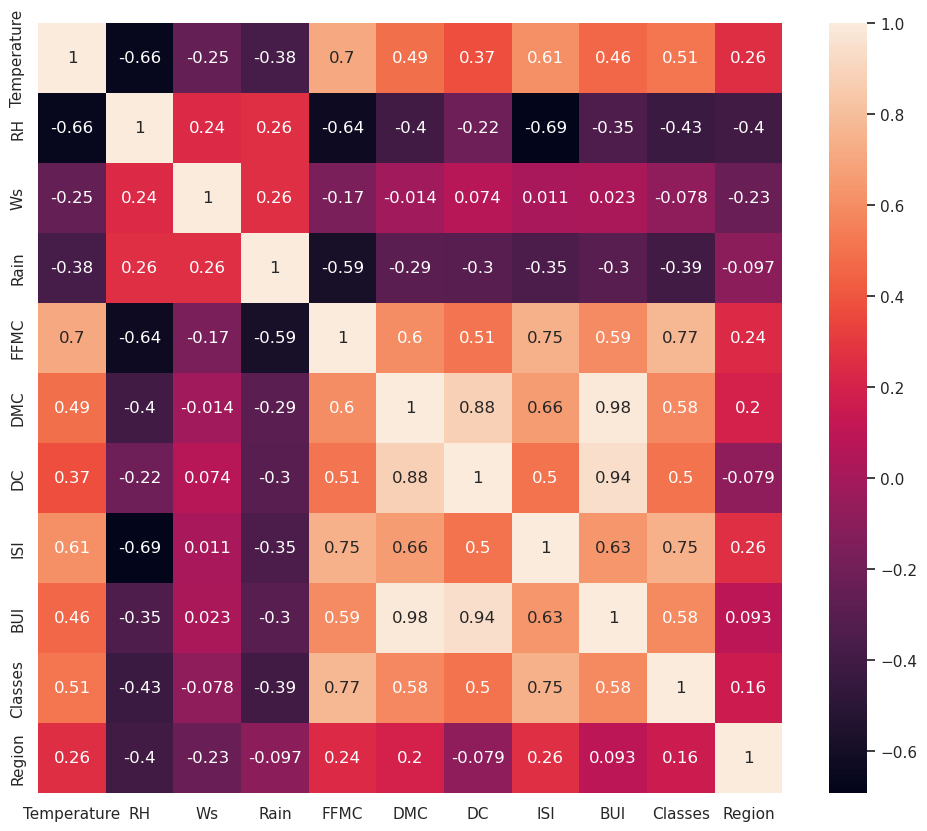

In [298]:
## Check for multicollinearity
plt.figure(figsize=(12,10))
corr=X_train.corr()
sns.heatmap(corr,annot=True)

In [299]:
## fcuntion to find highly correlated features 
def correlation(dataset, threshold):
    col_corr = set()
    corr_matrix = dataset.corr()
    for i in range(len(corr_matrix.columns)):
        for j in range(i):
            if abs(corr_matrix.iloc[i, j]) > threshold: 
                colname = corr_matrix.columns[i]
                col_corr.add(colname)
    return col_corr

In [300]:
corr_features=correlation(X_train,0.80) ## lets take threshold as 80%
corr_features

{'BUI', 'DC'}

In [301]:
## drop highly correlated features from both x test and x train 
X_train.drop(corr_features,axis=1,inplace=True)
X_test.drop(corr_features,axis=1,inplace=True)
X_train.shape,X_test.shape

((183, 9), (61, 9))

### scaling and standardisation 

In [302]:
from sklearn.preprocessing import StandardScaler
ss=StandardScaler()

In [310]:
X_train_scaled=ss.fit_transform(X_train)
X_test_scaled=ss.transform(X_test)

In [311]:
X_train_scaled

array([[-0.81085018,  0.16311382,  1.29231566, ..., -0.77409606,
        -1.1098231 , -1.00547949],
       [ 1.06405791, -0.44884168,  0.15167049, ...,  0.84971776,
         0.9010445 ,  0.99455037],
       [-0.27516216,  0.63907922, -0.60875963, ..., -0.21666743,
         0.9010445 ,  0.99455037],
       ...,
       [-1.88222624,  0.91105944,  0.53188555, ..., -1.08916441,
        -1.1098231 , -1.00547949],
       [ 0.26052587, -0.38084663,  0.15167049, ...,  0.48617735,
         0.9010445 ,  0.99455037],
       [-0.54300617,  0.9790545 ,  2.05274578, ..., -0.87104017,
        -1.1098231 , -1.00547949]])

In [312]:
X_test_scaled

array([[-2.75162156e-01,  9.51187672e-02, -2.28544571e-01,
        -3.81132246e-01,  6.38241722e-01, -4.01362602e-02,
         2.43817082e-01,  9.01044498e-01, -1.00547949e+00],
       [ 2.60525871e-01, -5.84831795e-01, -9.88974688e-01,
        -3.81132246e-01,  7.42136256e-01, -3.84555270e-01,
         4.13469272e-01,  9.01044498e-01, -1.00547949e+00],
       [ 2.60525871e-01, -9.92802132e-01,  1.51670488e-01,
        -3.81132246e-01,  7.00578442e-01, -5.44750158e-01,
         5.10413381e-01,  9.01044498e-01,  9.94550368e-01],
       [ 7.96213899e-01, -6.52826851e-01,  5.31885546e-01,
        -1.47707879e-01,  1.88032075e-01,  4.80497126e-01,
        -4.83263733e-01,  9.01044498e-01,  9.94550368e-01],
       [ 2.13543397e+00, -1.46876753e+00, -2.12961986e+00,
        -3.34447373e-01,  1.00533574e+00,  6.32682270e-01,
         1.16478612e+00,  9.01044498e-01,  9.94550368e-01],
       [ 1.86758995e+00,  9.51187672e-02, -2.50983492e+00,
         1.79086236e-01, -2.55251270e-01, -2.403798

## seeing effects of scaling 

Text(0.5, 1.0, 'X_train After Scaling')

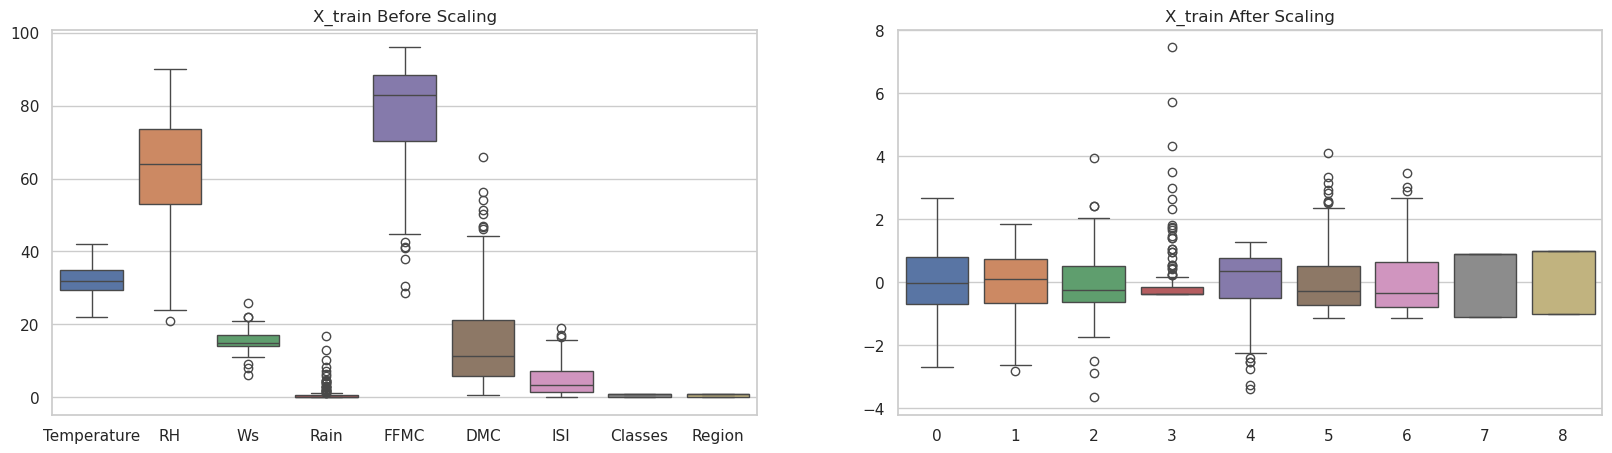

In [313]:
plt.subplots(figsize=(20, 5))
plt.axis('off')
plt.subplot(1, 2, 1)
sns.boxplot(data=X_train)
plt.title('X_train Before Scaling')
plt.subplot(1, 2, 2)
sns.boxplot(data=X_train_scaled)
plt.title('X_train After Scaling')


## Linear regression model 

In [314]:
from sklearn.linear_model import LinearRegression
lr=LinearRegression()

In [315]:
lr.fit(X_train_scaled,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [316]:
y_pred=lr.predict(X_test_scaled)

In [317]:
y_pred,y_train

(array([ 8.26435343,  7.75659021,  6.98143169,  6.45492377, 13.84383674,
         1.15502058, 10.73468367, -1.0483081 ,  1.59520107, -0.4275356 ,
         0.48205207,  4.13406583,  1.60342909,  1.30953788, 18.46529556,
         6.73604135, 24.90479942, -0.07716306,  7.26703269,  5.06724158,
         1.4802323 ,  0.22841643,  8.10107266,  0.3412048 , 20.94393446,
         0.08666419,  5.97439337,  9.84194441,  3.67481266, 14.9951814 ,
         8.50238647, -0.66191218, 10.47518194, 14.56532935,  1.40046462,
         1.49642877,  0.85336586,  6.0171077 , -0.77544288, -0.06204607,
         6.67997504,  3.04439533,  3.25031811, -0.24493846, 15.3024311 ,
         8.40630034,  8.35118046,  1.31583277, 10.39854916,  9.25655418,
        29.11555687,  2.21370633,  7.85700968, 19.31501388, 13.91763021,
        16.14607404, 28.93438872, -0.26578769, -0.33550125, 14.42537696,
         9.89396186]),
 115     0.7
 181    13.2
 225     3.9
 68      2.6
 104     0.0
        ... 
 106     0.0
 14      0

## perfomance checking of model 

In [318]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [319]:
mse=mean_squared_error(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
rmse=np.sqrt(mse)
r2=r2_score(y_test,y_pred)
print ("Mean squared error :", mse)
print ("Mean absolute error :", mae)
print ("Root Mean squared error :", rmse)
print ("R square score :", r2)

Mean squared error : 0.5604072092821957
Mean absolute error : 0.5516452785962694
Root Mean squared error : 0.7486035060579103
R square score : 0.990325441548238


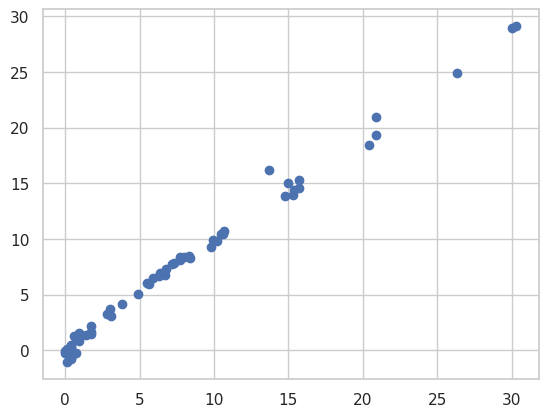

In [320]:
plt.scatter(y_test,y_pred)

## Applying other metrics of LR 
1. Lasso
2. Cross Validation Lasso
3. Ridge
4. Cross validation Ridge
5. Elastic Net
6. EN with Cross validation 

Mean squared error : 2.7388108602883774
Mean absolute error : 1.1862508609509752
Root Mean squared error : 1.6549353039585497
R square score : 0.9527186921986258


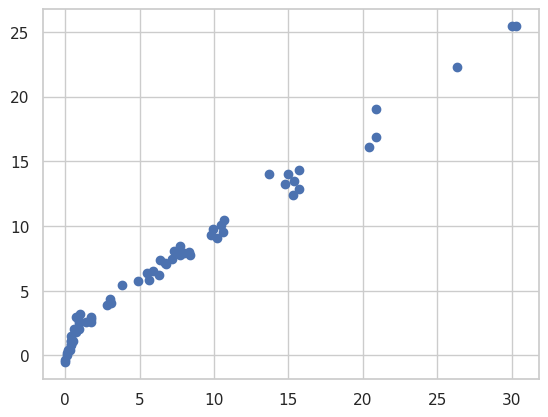

In [323]:
## Lasso
from sklearn.linear_model import Lasso
lasso=Lasso()
lasso.fit(X_train_scaled,y_train)
y_pred=lasso.predict(X_test_scaled)
plt.scatter(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
rmse=np.sqrt(mse)
r2=r2_score(y_test,y_pred)
print ("Mean squared error :", mse)
print ("Mean absolute error :", mae)
print ("Root Mean squared error :", rmse)
print ("R square score :", r2)

Mean squared error : 0.6024533295523122
Mean absolute error : 0.590225550670557
Root Mean squared error : 0.776178671152662
R square score : 0.989599580707254


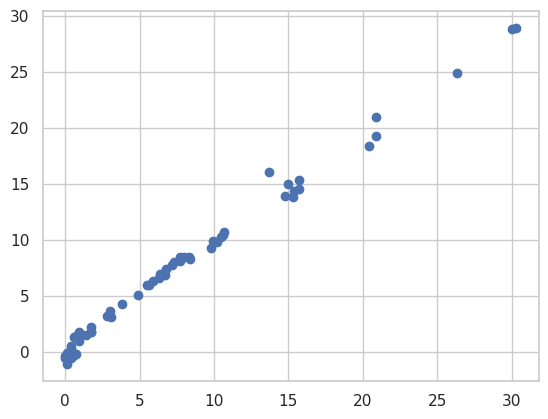

In [325]:
### Lasso CV
from sklearn.linear_model import LassoCV
lassocv=LassoCV(cv=5)
lassocv.fit(X_train_scaled,y_train)
y_pred=lassocv.predict(X_test_scaled)
plt.scatter(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
rmse=np.sqrt(mse)
r2=r2_score(y_test,y_pred)
print ("Mean squared error :", mse)
print ("Mean absolute error :", mae)
print ("Root Mean squared error :", rmse)
print ("R square score :", r2)

Mean squared error : 0.5994739929606651
Mean absolute error : 0.5779554428412216
Root Mean squared error : 0.7742570587089698
R square score : 0.9896510143175394


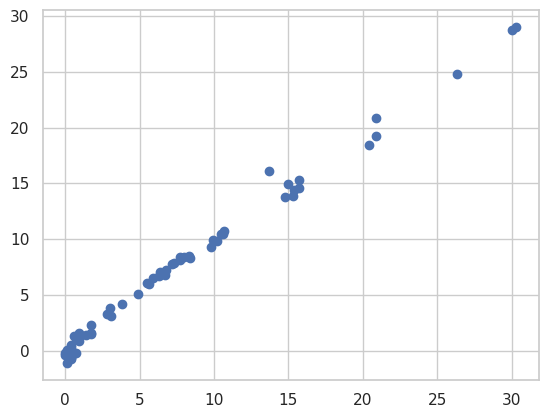

In [326]:
## Ridge
from sklearn.linear_model import Ridge
ridge=Ridge()
ridge.fit(X_train_scaled,y_train)
y_pred=ridge.predict(X_test_scaled)
plt.scatter(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
rmse=np.sqrt(mse)
r2=r2_score(y_test,y_pred)
print ("Mean squared error :", mse)
print ("Mean absolute error :", mae)
print ("Root Mean squared error :", rmse)
print ("R square score :", r2)

Mean squared error : 0.5994739929606651
Mean absolute error : 0.5779554428412216
Root Mean squared error : 0.7742570587089698
R square score : 0.9896510143175394


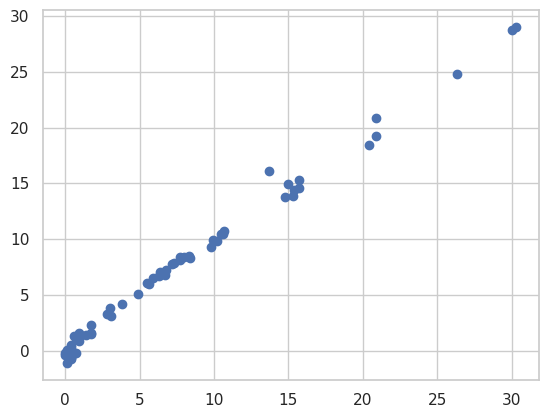

In [327]:
## Ridge CV
from sklearn.linear_model import RidgeCV
ridgecv=RidgeCV(cv=5)
ridgecv.fit(X_train_scaled,y_train)
y_pred=ridgecv.predict(X_test_scaled)
plt.scatter(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
rmse=np.sqrt(mse)
r2=r2_score(y_test,y_pred)
print ("Mean squared error :", mse)
print ("Mean absolute error :", mae)
print ("Root Mean squared error :", rmse)
print ("R square score :", r2)

In [328]:
ridgecv.get_params()

{'alpha_per_target': False,
 'alphas': (0.1, 1.0, 10.0),
 'cv': 5,
 'fit_intercept': True,
 'gcv_mode': None,
 'scoring': None,
 'store_cv_results': False}

Mean squared error : 7.086715440207197
Mean absolute error : 1.9100570629061815
Root Mean squared error : 2.6620885485286165
R square score : 0.8776588851433474


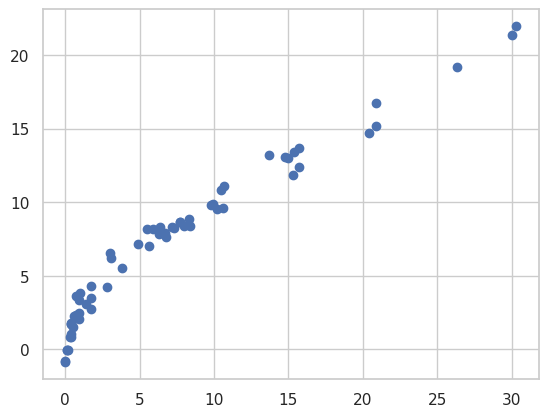

In [329]:
## Elastic Net 
from sklearn.linear_model import ElasticNet
en=ElasticNet()
en.fit(X_train_scaled,y_train)
y_pred=en.predict(X_test_scaled)
plt.scatter(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
rmse=np.sqrt(mse)
r2=r2_score(y_test,y_pred)
print ("Mean squared error :", mse)
print ("Mean absolute error :", mae)
print ("Root Mean squared error :", rmse)
print ("R square score :", r2)


Mean squared error : 0.7008538912455387
Mean absolute error : 0.6486859437316491
Root Mean squared error : 0.8371701686309293
R square score : 0.9879008481249114


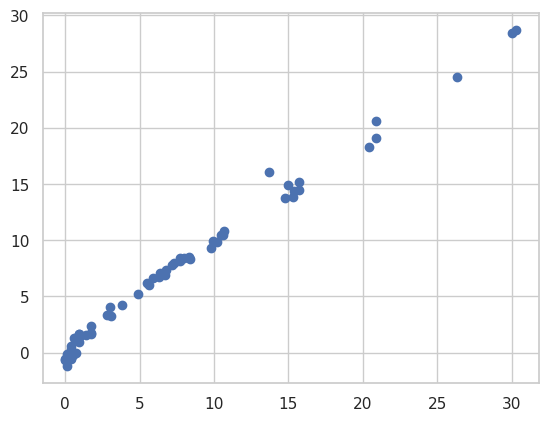

In [330]:
## Elastic Net CV
from sklearn.linear_model import ElasticNetCV
encv=ElasticNetCV(cv=10)
encv.fit(X_train_scaled,y_train)
y_pred=encv.predict(X_test_scaled)
plt.scatter(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
rmse=np.sqrt(mse)
r2=r2_score(y_test,y_pred)
print ("Mean squared error :", mse)
print ("Mean absolute error :", mae)
print ("Root Mean squared error :", rmse)
print ("R square score :", r2)

In [331]:
encv.get_params()

{'alphas': 'warn',
 'copy_X': True,
 'cv': 10,
 'eps': 0.001,
 'fit_intercept': True,
 'l1_ratio': 0.5,
 'max_iter': 1000,
 'n_alphas': 'deprecated',
 'n_jobs': None,
 'positive': False,
 'precompute': 'auto',
 'random_state': None,
 'selection': 'cyclic',
 'tol': 0.0001,
 'verbose': 0}

In [333]:
encv.alpha_


0.028888627686000735